# 06 — Persiapan representasi teks

Tahap ini memastikan setiap algoritma menggunakan dokumen dan query yang sama. Model BM25/TF-IDF akan memanfaatkan istilah, sedangkan FastText/E5/BGE-M3 memakai representasi vektor. Perbedaan preprocessing dijelaskan, tetapi sumber metadata tetap sama.

## 1. Memuat input dari notebook 04 dan 05

In [1]:
from pathlib import Path
import re, html, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'data' / 'dataset_buku_2000.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'dataset_buku_2000.csv').exists(), 'Buka folder utama proyek atau notebook dari subfolder notebooks.'
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
FIG = ROOT / 'figures'
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
books = pd.read_csv(DATA / 'dataset_buku_2000.csv', dtype=str).fillna('')
comps = pd.read_csv(DATA / 'competencies_green.csv', dtype=str).fillna('')
print(f'Buku: {len(books):,} | Kompetensi: {len(comps)}')

Buku: 973 | Kompetensi: 67


In [2]:
doc=pd.read_csv(OUT/'dataset_buku_bersih.csv',dtype=str).fillna('')
q=pd.read_csv(OUT/'profil_kompetensi_query.csv',dtype=str).fillna('')
assert len(doc)==len(books) and len(q)==len(comps)
print('Jumlah pasangan yang akan dinilai:',len(doc)*len(q))

Jumlah pasangan yang akan dinilai: 65191


## 2. Contoh token dan bobot istilah

In [3]:
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer

def token_sederhana(text):
    return re.findall(r'[a-zA-Z]{2,}',str(text).lower())

kata_buku=token_sederhana(doc.teks_model.iloc[0])
kata_query=token_sederhana(q.teks_query.iloc[0])
print('Contoh 20 token buku:',kata_buku[:20])
print('Token kompetensi:',kata_query)
print('Frekuensi istilah buku (10 teratas):',Counter(kata_buku).most_common(10))

Contoh 20 token buku: ['business', 'growth', 'strategy', 'business', 'growth', 'strategy', 'introduction', 'wrote', 'this', 'book', 'business', 'growth', 'strategy', 'to', 'help', 'entrepreneurs', 'learn', 'how', 'to', 'grow']
Token kompetensi: ['business', 'development', 'business', 'growth', 'business', 'strategy', 'market', 'opportunities']
Frekuensi istilah buku (10 teratas): [('growth', 18), ('business', 17), ('to', 16), ('and', 14), ('the', 9), ('you', 9), ('strategy', 8), ('is', 8), ('for', 8), ('value', 7)]


## 3. Membentuk TF-IDF dan melihat dimensi
Di sini TF-IDF hanya dipakai untuk inspeksi fitur; eksperimen penuh ada pada notebook 08.

In [4]:
vectorizer=TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=40000,sublinear_tf=True)
matriks_buku=vectorizer.fit_transform(doc.teks_model)
matriks_query=vectorizer.transform(q.teks_query)
print('Matriks buku:',matriks_buku.shape)
print('Matriks query:',matriks_query.shape)
print('Jumlah istilah:',len(vectorizer.get_feature_names_out()))
assert matriks_buku.shape[0]==len(doc)
assert matriks_query.shape[1]==matriks_buku.shape[1]

Matriks buku: (973, 40000)
Matriks query: (67, 40000)
Jumlah istilah: 40000


## 4. Lihat istilah dengan bobot tertinggi untuk satu buku

In [5]:
baris=matriks_buku.getrow(0)
urut=np.argsort(-baris.data)[:12]
term=vectorizer.get_feature_names_out()
tabel=pd.DataFrame({'istilah':term[baris.indices[urut]],'bobot_tfidf':baris.data[urut]})
display(tabel)

,istilah,bobot_tfidf
0,growth strategy,0.161767
1,business growth,0.161541
2,growth,0.145663
3,sustain growth,0.139368
4,sustain,0.138272
5,create value,0.131507
6,growth strategies,0.115079
7,grow business,0.112441
8,grow sustain,0.112441
9,grow,0.107710


## 5. Periksa panjang teks untuk perencanaan transformer

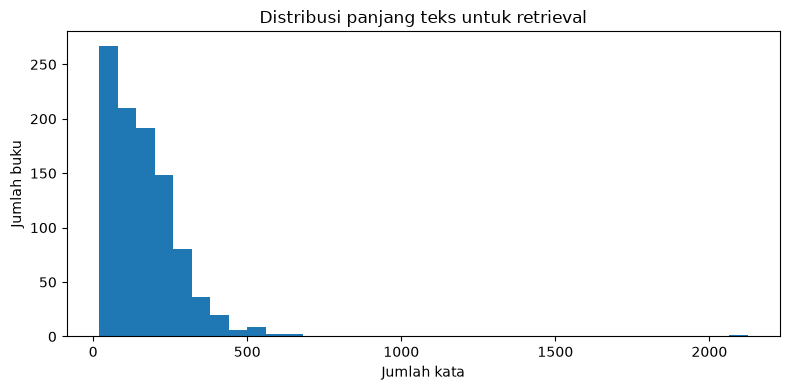

Panjang median: 144 | P95: 359


In [6]:
panjang = pd.Series(
    [len(texto.split()) for texto in doc['teks_model'].fillna('').astype(str)],
    index=doc.index,
    name='teks_model'
)
fig,ax=plt.subplots(figsize=(8,4));ax.hist(panjang,bins=35)
ax.set(title='Distribusi panjang teks untuk retrieval',xlabel='Jumlah kata',ylabel='Jumlah buku')
plt.tight_layout();plt.savefig(FIG/'06_panjang_teks.png',dpi=160);plt.show()
print('Panjang median:',int(panjang.median()),'| P95:',int(panjang.quantile(.95)))

## 6. Daftar identitas untuk menjaga urutan matriks

In [7]:
doc[['book_id','teks_model']].to_csv(OUT/'korpus_model.csv',index=False,encoding='utf-8-sig')
q[['competency_id','teks_query']].to_csv(OUT/'query_model.csv',index=False,encoding='utf-8-sig')
assert np.array_equal(doc['book_id'].to_numpy(), books['book_id'].to_numpy())
print('Input bersama disimpan. Notebook algoritma selanjutnya wajib menjaga urutan ID ini.')

Input bersama disimpan. Notebook algoritma selanjutnya wajib menjaga urutan ID ini.


## Kesimpulan tahap
Korpus dan query bersama telah dibuat. Tahap 07–11 menghitung skor menggunakan pendekatan masing-masing tanpa mengubah pasangan yang menjadi dasar pengujian.